# 04 · Our model: YOLO26n vs the baseline

How well does our trained model count cells, and does it beat the baseline? This notebook scores **YOLO26n trained on our boxes** with the same metrics and the same split (`splits/splits.csv`) as the baselines in `02_baseline_cellpose.ipynb`. How the model is trained, and which augmentations help, is covered in `03_initial_model_train.ipynb` and `03b_augmentation_exploration.ipynb`.

| | Model | Learns from |
|---|---|---|
| B0 | Per-session mean count (the "recognize the session" shortcut) | session label |
| B2 | Cellpose-SAM, three numbers tuned on train (**the baseline**, from notebook 02) | three settings only |
| **Ours** | **YOLO26n, fine-tuned on our boxes with default Ultralytics settings** | **every labelled box** |

All models are scored on the **random split** (`split == "test"`, 75 images), the same test images as notebook 02.

Results go to `outputs/results/yolo_performance.csv`, figures to `outputs/figures/yolo_performance/`. The B2 rows are read from `outputs/results/baseline_cellpose.csv`, so run notebook 02 first. Needs the modeling extras: `pip install -e ".[dev,model]"`. Training (100 epochs) is skipped when the weights already exist in `outputs/yolo/yolo26n_default/`.


In [1]:
# --- Bootstrap (identical in every notebook). Does nothing when run locally. ---
# On Colab: mounts Google Drive (data/ and outputs/ live there), clones or updates the repo,
# and installs the `cellcount` utils. Secrets: add ROBOFLOW_EXPORT_URL (and GH_TOKEN if the
# repo is private) under the key icon in the left sidebar, with notebook access enabled.
import os, subprocess, sys

REPO_URL = "https://github.com/Erdos-Projects/fall-2026-automated-cell-counting.git"
BRANCH = "main"  # set to a feature branch to try unmerged work

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata

    drive.mount("/content/drive")
    repo = "/content/fall-2026-automated-cell-counting"
    try:
        url = REPO_URL.replace("https://", f"https://{userdata.get('GH_TOKEN')}@")
    except Exception:
        url = REPO_URL
    cmd = ["git", "-C", repo, "pull", "-q"] if os.path.exists(repo) else ["git", "clone", "-q", "-b", BRANCH, url, repo]
    if subprocess.run(cmd).returncode != 0:
        raise RuntimeError("git clone/pull failed: check BRANCH and the GH_TOKEN secret")
    # [model] adds cellpose (torch is preinstalled on Colab)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", f"{repo}[model]"], check=True)
    sys.path.insert(0, f"{repo}/src")  # import without restarting the runtime
    os.chdir(repo)

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from cellcount import baselines, viz, yolo
from cellcount.config import get_paths
from cellcount.data import RAW_DIRNAME, load_coco
from cellcount.eda import count_bins
from cellcount.metrics import count_metrics, count_metrics_by, detection_metrics, per_image_counts
from cellcount.splits import leave_one_source_out, load_splits

sns.set_theme(style="whitegrid", context="notebook")
paths = get_paths()
FIG = paths.outputs / "figures" / "yolo_performance"
FIG.mkdir(parents=True, exist_ok=True)
(paths.outputs / "results").mkdir(exist_ok=True)

images, boxes = load_coco(paths.data / RAW_DIRNAME)
split_df = load_splits(paths.root / "splits" / "splits.csv")
truth = per_image_counts(boxes, images["uid"]).rename(columns={"live": "live_true", "dead": "dead_true"})
df = (images[["uid", "path", "width", "height", "source"]]
      .merge(split_df[["uid", "split"]], on="uid")
      .merge(truth, on="uid"))
df["total_true"] = df["live_true"] + df["dead_true"]
df["count_bin"] = count_bins(df["total_true"])
train, valid, test = (df[df["split"] == s] for s in ("train", "valid", "test"))
print(df["split"].value_counts().to_dict(), "| sessions:", df["source"].nunique())

{'train': 351, 'test': 75, 'valid': 74} | sessions: 5


In [3]:
results = []   # one row per method x test level x fold
preds = {}     # per-image predictions on the random-split test, for the figures


def with_counts(frame, pred_boxes):
    """Attach live_pred / dead_pred from predicted boxes to a per-image frame."""
    c = per_image_counts(pred_boxes, frame["uid"]).rename(columns={"live": "live_pred", "dead": "dead_pred"})
    return frame.merge(c, on="uid")


def evaluate(method, level, fold, counted, pred_boxes=None):
    row = {"method": method, "level": level, "fold": fold, **count_metrics(counted)}
    if pred_boxes is not None:
        det = detection_metrics(pred_boxes[pred_boxes["uid"].isin(counted["uid"])],
                                boxes[boxes["uid"].isin(counted["uid"])])
        for cls, m in det.iterrows():
            row.update({f"{k}_{cls.lower()}": m[k] for k in ("precision", "recall", "f1")})
    results.append(row)
    return row

## B0: reference baseline

On the random split, B0 shows how much the session alone explains. Under leave-one-session-out the held-out session is unseen, so B0 falls back to the training-set mean.

In [4]:
for name, fn in [("B0 session mean", baselines.predict_session_mean)]:
    preds[name] = fn(train, test)
    evaluate(name, "random split", "test", preds[name])
    loso = pd.concat([fn(tr, te) for _, tr, te in leave_one_source_out(df)])
    evaluate(name, "leave-one-session-out", "pooled", loso)
pd.DataFrame(results).set_index(["method", "level"])[["mae_total", "mae_dead", "r2_total", "within_10pct"]].round(3)

mae_total  mae_dead  r2_total  \
method          level                                                  
B0 session mean random split               6.854     1.147     0.705   
                leave-one-session-out     14.629     1.185    -0.403   

                                       within_10pct  
method          level                                
B0 session mean random split                  0.453  
                leave-one-session-out         0.204

## Our model: YOLO26n, fine-tuned with default settings

Exports our split to YOLO format (images are symlinks) and fine-tunes the COCO-pretrained nano model for 100 epochs at 640 px. The confidence threshold is then chosen to minimize total-count MAE on **valid**, so the test images play no part in any choice. Training takes about 15–30 min on a Colab T4 (about an hour on an M5 Pro) and is skipped when the weights exist.


In [5]:
data_yaml = yolo.export_yolo(images, boxes, split_df, paths.data / "yolo")
weights = paths.outputs / "yolo" / "yolo26n_default" / "weights" / "best.pt"
if not weights.exists():
    weights = yolo.train(data_yaml, paths.outputs / "yolo", model="yolo26n.pt", name="yolo26n_default")

yolo_boxes = yolo.predict(weights, pd.concat([valid, test]))
conf_t = yolo.tune_conf(yolo_boxes[yolo_boxes["uid"].isin(valid["uid"])], valid)
yolo_kept = yolo_boxes[yolo_boxes["conf"] >= conf_t]
print(f"confidence threshold (tuned on valid) = {conf_t:.2f}")

preds["YOLO26n (ours)"] = with_counts(test, yolo_kept)
evaluate("YOLO26n (ours)", "random split", "test", preds["YOLO26n (ours)"], yolo_kept)

confidence threshold (tuned on valid) = 0.63


{'method': 'YOLO26n (ours)',
 'level': 'random split',
 'fold': 'test',
 'n_images': np.float64(75.0),
 'mae_live': np.float64(1.5866666666666667),
 'mae_dead': np.float64(0.56),
 'mae_total': np.float64(1.6133333333333333),
 'bias_total': np.float64(-0.04),
 'rmse_total': np.float64(2.1571586249817916),
 'rel_err_total': np.float64(0.03188414450103167),
 'within_10pct': np.float64(0.96),
 'r2_total': np.float64(0.9787899708772322),
 'viability_err_pp': np.float64(1.220340949309228),
 'precision_live': np.float64(0.9501312335958005),
 'recall_live': np.float64(0.9599575709360912),
 'f1_live': np.float64(0.9550191267642791),
 'precision_dead': np.float64(0.9844961240310077),
 'recall_dead': np.float64(0.7426900584795322),
 'f1_dead': np.float64(0.8466666666666667),
 'precision_cell': np.float64(0.9517644072099518),
 'recall_cell': np.float64(0.9510400811770675),
 'f1_cell': np.float64(0.9514021063316839)}

Training curves from Ultralytics (loss and mAP per epoch on valid):

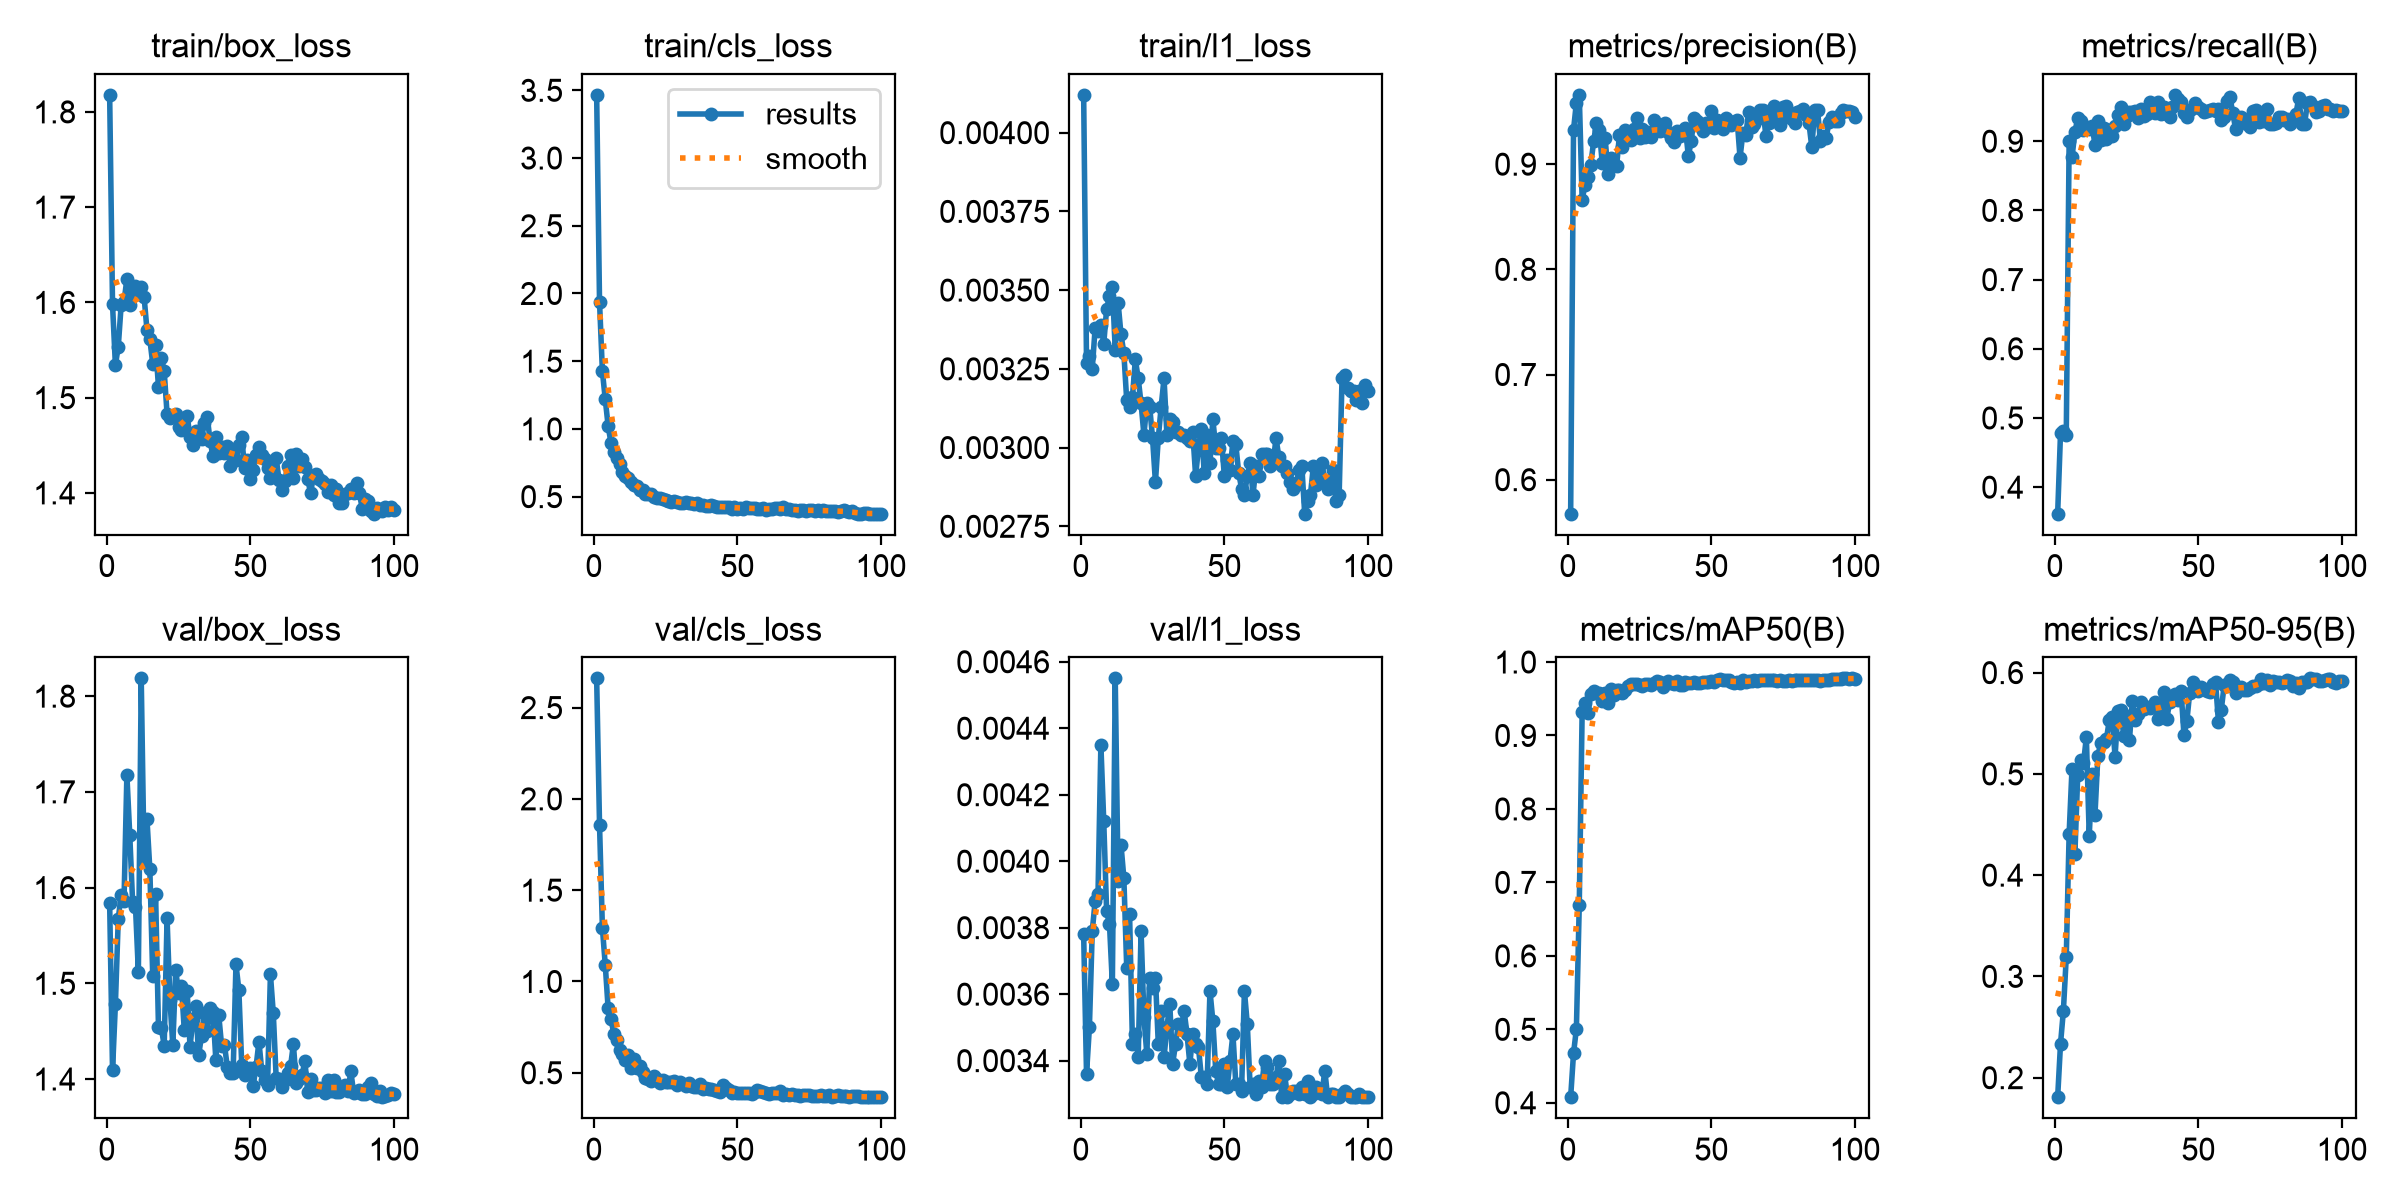

In [6]:
from IPython.display import Image, display

display(Image(filename=str(weights.parents[1] / "results.png"), width=900))

## Results table

In [7]:
res = pd.DataFrame(results)
res.to_csv(paths.outputs / "results" / "yolo_performance.csv", index=False)

cols = ["mae_total", "mae_live", "mae_dead", "viability_err_pp", "within_10pct", "r2_total",
        "precision_cell", "recall_cell", "f1_live", "f1_dead"]
summary = res[res["fold"].isin(["test", "pooled"])].set_index(["level", "method"])[cols]
summary.round(3)

,,mae_total,mae_live,mae_dead,viability_err_pp,within_10pct,r2_total,precision_cell,recall_cell,f1_live,f1_dead
level,method,,,,,,,,,,
random split,B0 session mean,6.854,6.860,1.147,2.328,0.453,0.705,NaN,NaN,NaN,NaN
leave-one-session-out,B0 session mean,14.629,14.215,1.185,2.225,0.204,-0.403,NaN,NaN,NaN,NaN
random split,YOLO26n (ours),1.613,1.587,0.560,1.220,0.960,0.979,0.952,0.951,0.955,0.847


## Our model vs the baseline

The B2 Cellpose-SAM rows come from notebook 02's results file. All rows use the same 75 test images and the same total-count metrics.


In [8]:
base = pd.read_csv(paths.outputs / "results" / "baseline_cellpose.csv")
base = base[base["method"].str.startswith("B2") & base["fold"].isin(["test", "pooled"])]
cmp_cols = ["mae_total", "bias_total", "within_10pct", "r2_total"]
compare = (pd.concat([res[res["fold"].isin(["test", "pooled"])], base])
           .set_index(["level", "method"])[cmp_cols].sort_index())
compare.round(3)


mae_total  bias_total  \
level                 method                                                    
leave-one-session-out B0 session mean                      14.629      -0.000   
                      B2 Cellpose-SAM (tuned on train)      6.280      -1.064   
random split          B0 session mean                       6.854       1.702   
                      B2 Cellpose-SAM (tuned on train)      5.600      -0.640   
                      YOLO26n (ours)                        1.613      -0.040   

                                                        within_10pct  r2_total  
level                 method                                                    
leave-one-session-out B0 session mean                          0.204    -0.403  
                      B2 Cellpose-SAM (tuned on train)         0.616     0.583  
random split          B0 session mean                          0.453     0.705  
                      B2 Cellpose-SAM (tuned on train)         0.587     0.744  
                      YOLO26n (ours)                           0.960     0.979

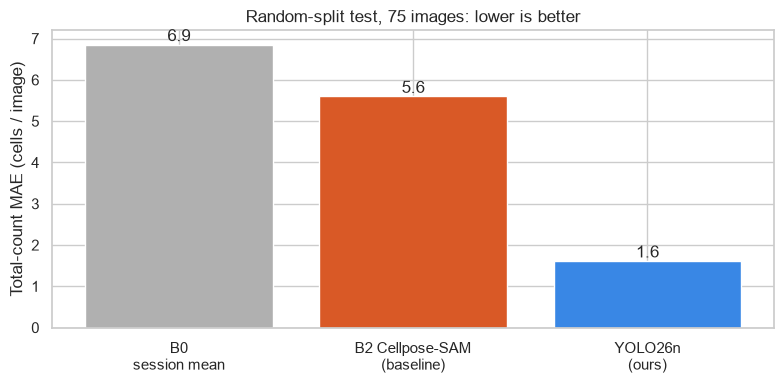

In [9]:
rs = compare.loc["random split"]
order = ["B0 session mean", rs.index[rs.index.str.startswith("B2")][0], "YOLO26n (ours)"]
fig, ax = plt.subplots(figsize=(8, 4))
vals = rs.loc[order, "mae_total"]
bars = ax.bar(["B0\nsession mean", "B2 Cellpose-SAM\n(baseline)", "YOLO26n\n(ours)"], vals,
              color=["#b0b0b0", "#d95926", "#3987e5"])
ax.bar_label(bars, fmt="%.1f")
ax.set(ylabel="Total-count MAE (cells / image)", title="Random-split test, 75 images: lower is better")
fig.tight_layout()
fig.savefig(FIG / "00_mae_vs_baseline.png", dpi=150)


## Diagnostics (random-split test)

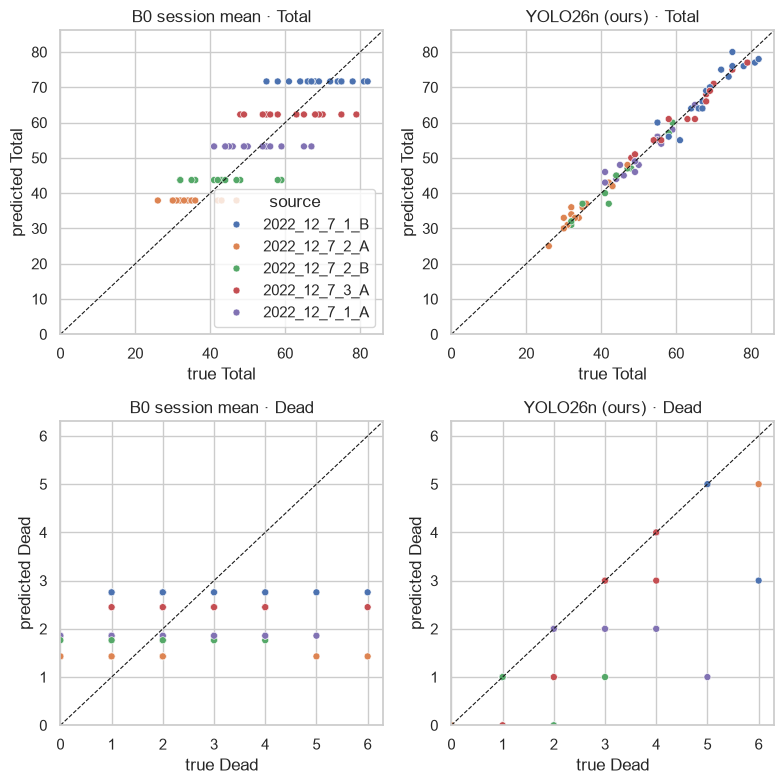

In [10]:
methods = list(preds)
fig, axes = plt.subplots(2, len(methods), figsize=(4 * len(methods), 8), squeeze=False)
for j, m in enumerate(methods):
    p = preds[m]
    for i, (t, q, label) in enumerate([("total_true", None, "Total"), ("dead_true", "dead_pred", "Dead")]):
        ax = axes[i, j]
        pred = p["live_pred"] + p["dead_pred"] if q is None else p[q]
        sns.scatterplot(x=p[t], y=pred, hue=p["source"], ax=ax, s=25, legend=(i == 0 and j == 0))
        lim = [0, max(p[t].max(), pred.max()) * 1.05]
        ax.plot(lim, lim, "k--", lw=0.8)
        ax.set(xlim=lim, ylim=lim, xlabel=f"true {label}", ylabel=f"predicted {label}", title=f"{m} · {label}")
fig.tight_layout()
fig.savefig(FIG / "01_pred_vs_true.png", dpi=150)

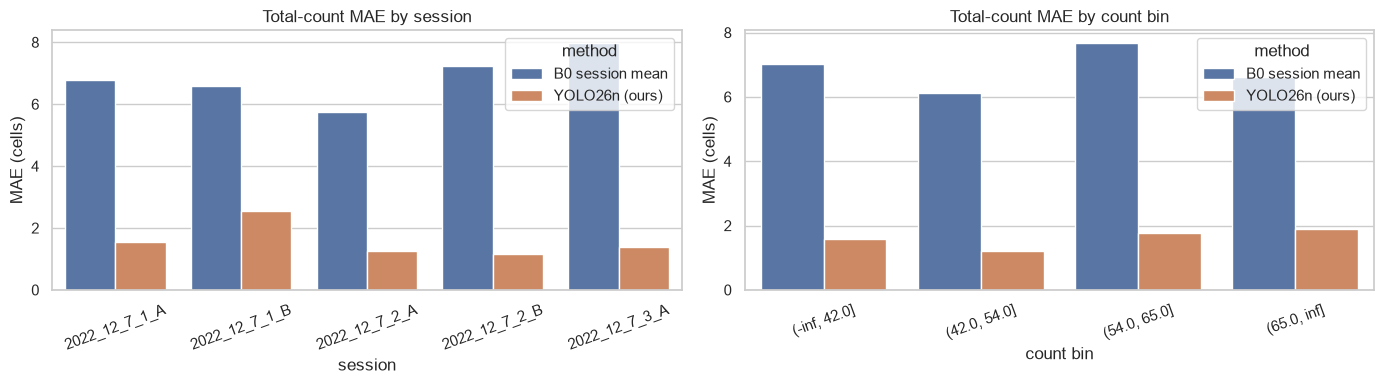

In [11]:
by = []
for m, p in preds.items():
    for col, name in [("source", "session"), ("count_bin", "count bin")]:
        g = count_metrics_by(p, p[col])[["mae_total"]].reset_index(names="group")
        by.append(g.assign(method=m, by=name, group=g["group"].astype(str)))
by = pd.concat(by)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, ["session", "count bin"]):
    sns.barplot(data=by[by["by"] == name], x="group", y="mae_total", hue="method", ax=ax)
    ax.set(title=f"Total-count MAE by {name}", xlabel=name, ylabel="MAE (cells)")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIG / "02_mae_by_session_and_count.png", dpi=150)

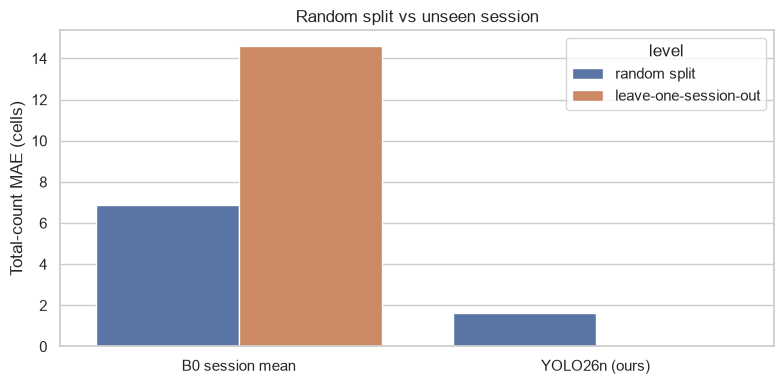

In [12]:
lv = res[res["fold"].isin(["test", "pooled"])]
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=lv, x="method", y="mae_total", hue="level", ax=ax)
ax.set(title="Random split vs unseen session", xlabel="", ylabel="Total-count MAE (cells)")
fig.tight_layout()
fig.savefig(FIG / "03_random_vs_loso.png", dpi=150)

**Worst test images** for our model (largest total-count error). Yellow: labelled boxes. Cyan / magenta: predicted Live / Dead.

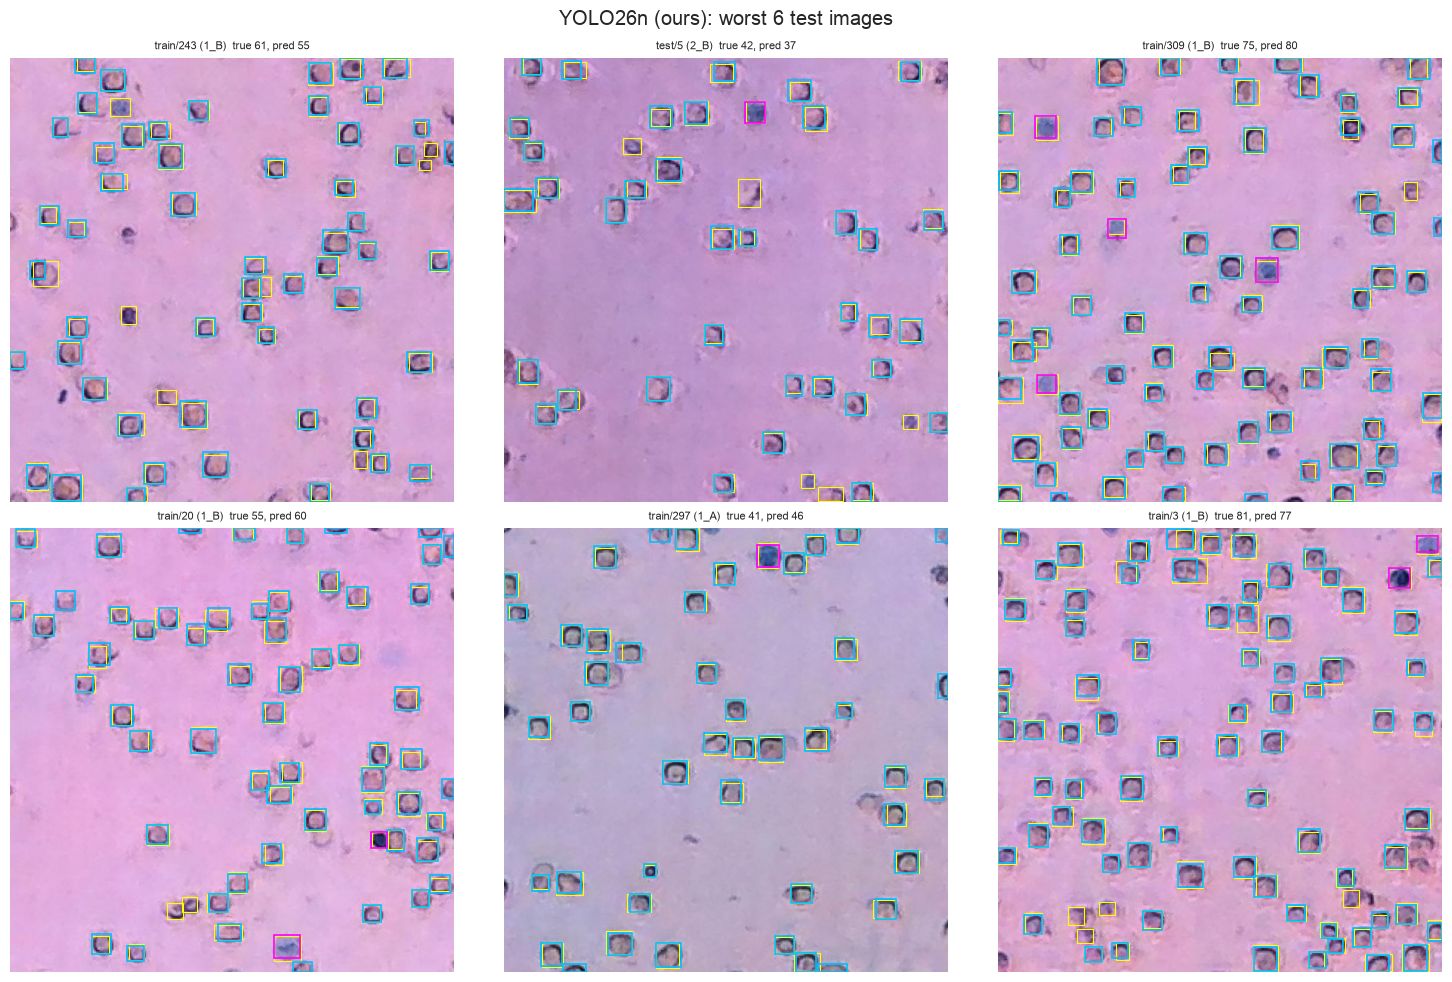

In [13]:
by_uid = df.set_index("uid", drop=False)
m = "YOLO26n (ours)"
p = preds[m].assign(err=lambda d: d["live_pred"] + d["dead_pred"] - d["total_true"])
worst = p.reindex(p["err"].abs().sort_values(ascending=False).index).head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, r in zip(axes.flat, worst.itertuples()):
    viz.show_prediction(by_uid.loc[r.uid], boxes, yolo_kept, ax=ax,
                        title=f"{r.uid} ({r.source[-3:]})  true {r.total_true}, pred {r.live_pred + r.dead_pred:.0f}")
fig.suptitle(f"{m}: worst 6 test images")
fig.tight_layout()
fig.savefig(FIG / "04_worst_yolo.png", dpi=120)

## Inference time per image

Measured on the machine that runs the notebook, excluding model loading. The time we report, 28.6 ms per image, was measured on a Google Colab Tesla T4 GPU. Counting by hand takes roughly a minute or more per image.


In [14]:
sample = test.head(20)
yolo.predict(weights, sample.head(1))  # warm-up
t0 = time.perf_counter()
yolo.predict(weights, sample)
yolo_sec = (time.perf_counter() - t0) / len(sample)
print(f"YOLO26n (ours): {yolo_sec:.3f} s per image (B2 Cellpose-SAM: about 1.8 s)")

YOLO26n (ours): 0.020 s per image (B2 Cellpose-SAM: about 1.8 s)


## Summary

Random-split test, 75 images (B2 from notebook 02):

| Model | Total MAE | Bias | Within ±10% | R² | Time / image |
|---|---|---|---|---|---|
| B0 session mean | 6.9 | +1.7 | 45% | 0.71 | — |
| B2 Cellpose-SAM, tuned on train (baseline) | 5.6 | −0.6 | 59% | 0.74 | 1.8 s |
| **YOLO26n (ours)** | **1.6** | **−0.04** | **96%** | **0.98** | **28.6 ms** (Colab T4) |

- **Our model cuts the baseline's count error by about 3.5×** (5.6 → 1.6 cells per image) and is about 63× faster.
- Its worst test images are off by 4–6 cells, mostly faint cells that the annotators labelled inconsistently.
- Dead cells are its weak spot: precision 0.98 but recall 0.74 (F1 0.85, vs 0.96 for Live).
